# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** : зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці : **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix,ConfusionMatrixDisplay
from IPython.display import display,Markdown

keras.utils.set_random_seed(42)
print('TensorFlow:',tf.__version__)
print('Keras:',keras.__version__)

TensorFlow: 2.20.0
Keras: 3.15.1


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
(x_train_raw,y_train_all),(x_test_raw,y_test)=keras.datasets.fashion_mnist.load_data()
class_names=['Футболка / топ','Штани','Светр','Сукня','Пальто','Сандалі','Сорочка','Кросівки','Сумка','Черевики']
print('x_train:',x_train_raw.shape,'y_train:',y_train_all.shape)
print('x_test:',x_test_raw.shape,'y_test:',y_test.shape)
display(pd.Series(y_train_all).value_counts().sort_index().rename('Кількість train-зображень'))

    0/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step


       0/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   24576/26421880 ━━━━━━━━━━━━━━━━━━━━ 54s 2us/step

   49152/26421880 ━━━━━━━━━━━━━━━━━━━━ 1:02 2us/step

   81920/26421880 ━━━━━━━━━━━━━━━━━━━━ 1:10 3us/step

... (90 outputs left out)

4382720/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


x_train: (60000, 28, 28) y_train: (60000,)
x_test: (10000, 28, 28) y_test: (10000,)


0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: Кількість train-зображень, dtype: int64

### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

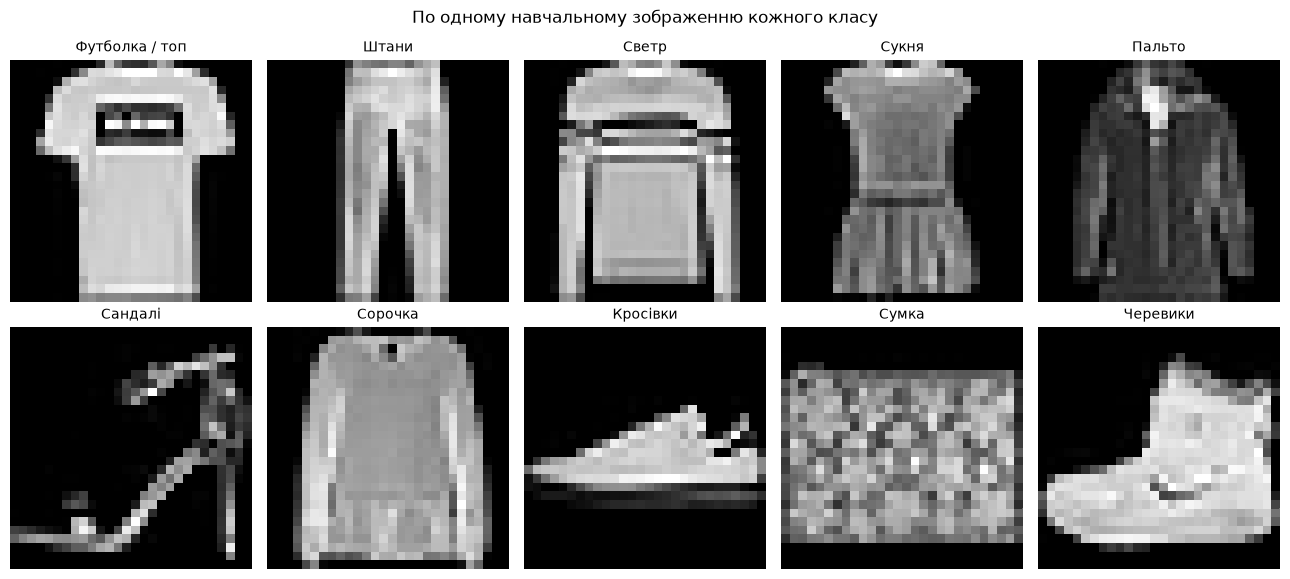

In [3]:
fig,axes=plt.subplots(2,5,figsize=(13,6))
for label,ax in enumerate(axes.flat):
    index=np.flatnonzero(y_train_all==label)[0]
    ax.imshow(x_train_raw[index],cmap='gray')
    ax.set_title(class_names[label],fontsize=10)
    ax.axis('off')
plt.suptitle('По одному навчальному зображенню кожного класу')
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
x_train_all=x_train_raw.astype('float32')/255.0
x_test=x_test_raw.astype('float32')/255.0
train_indices,val_indices=train_test_split(np.arange(len(y_train_all)),test_size=0.2,random_state=42,stratify=y_train_all)
x_train,y_train=x_train_all[train_indices],y_train_all[train_indices]
x_val,y_val=x_train_all[val_indices],y_train_all[val_indices]
print('Тип:',x_train.dtype)
print('Діапазон train:',x_train.min(),x_train.max())
print('Діапазон test:',x_test.min(),x_test.max())
print('Train:',len(x_train),'Validation:',len(x_val),'Test:',len(x_test))
print('Train та validation не перетинаються:',not np.intersect1d(train_indices,val_indices).size)

Тип: float32
Діапазон train: 0.0 1.0
Діапазон test: 0.0 1.0
Train: 48000 Validation: 12000 Test: 10000
Train та validation не перетинаються: True


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
model=keras.Sequential([
    keras.layers.Input(shape=(28,28)),
    keras.layers.Flatten(),
    keras.layers.Dense(256,activation='relu'),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(128,activation='relu'),
    keras.layers.Dropout(0.1),
    keras.layers.Dense(10,activation='softmax')
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
print('Модель скомпільовано')

Модель скомпільовано

**Вибір архітектури.** Два приховані шари на 256 і 128 нейронів дають змогу розпізнавати нелінійні поєднання пікселів без надмірно великої моделі. ReLU є простою функцією активації, Dropout 0,2 і 0,1 зменшує залежність від окремих нейронів. Adam із початковою швидкістю 0,001 використано як стандартний початковий варіант. Ці значення обрано до тестового оцінювання; у другому завданні перевіряються інші конфігурації.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
def make_callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=2,min_lr=0.00001)
    ]
history=model.fit(x_train,y_train,validation_data=(x_val,y_val),epochs=32,batch_size=128,callbacks=make_callbacks(),verbose=2)
print('Виконано епох:',len(history.history['loss']))

Epoch 1/32


375/375 - 4s - 12ms/step - accuracy: 0.7884 - loss: 0.5975 - val_accuracy: 0.8426 - val_loss: 0.4193 - learning_rate: 0.0010


Epoch 2/32


375/375 - 5s - 13ms/step - accuracy: 0.8471 - loss: 0.4158 - val_accuracy: 0.8623 - val_loss: 0.3759 - learning_rate: 0.0010


Epoch 3/32


375/375 - 5s - 14ms/step - accuracy: 0.8635 - loss: 0.3730 - val_accuracy: 0.8698 - val_loss: 0.3548 - learning_rate: 0.0010


... (55 outputs left out)

375/375 - 1s - 3ms/step - accuracy: 0.9284 - loss: 0.1937 - val_accuracy: 0.9029 - val_loss: 0.2799 - learning_rate: 1.5625e-05


Epoch 32/32


375/375 - 1s - 3ms/step - accuracy: 0.9256 - loss: 0.1946 - val_accuracy: 0.9031 - val_loss: 0.2801 - learning_rate: 1.5625e-05


Виконано епох: 32


### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
model.summary()
print('Шарів без Input:',len(model.layers))
print('Прихованих Dense-шарів:',2)
print('Параметрів:',model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Шарів без Input: 6
Прихованих Dense-шарів: 2
Параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
model_path=Path('fashion_mnist_base.keras')
model.save(model_path)
restored_model=keras.models.load_model(model_path)
np.testing.assert_allclose(model(x_val[:16],training=False).numpy(),restored_model(x_val[:16],training=False).numpy(),rtol=1e-5,atol=1e-6)
print('Модель збережено:',model_path)
print('Прогнози після повторного завантаження збігаються')

Модель збережено: fashion_mnist_base.keras
Прогнози після повторного завантаження збігаються


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

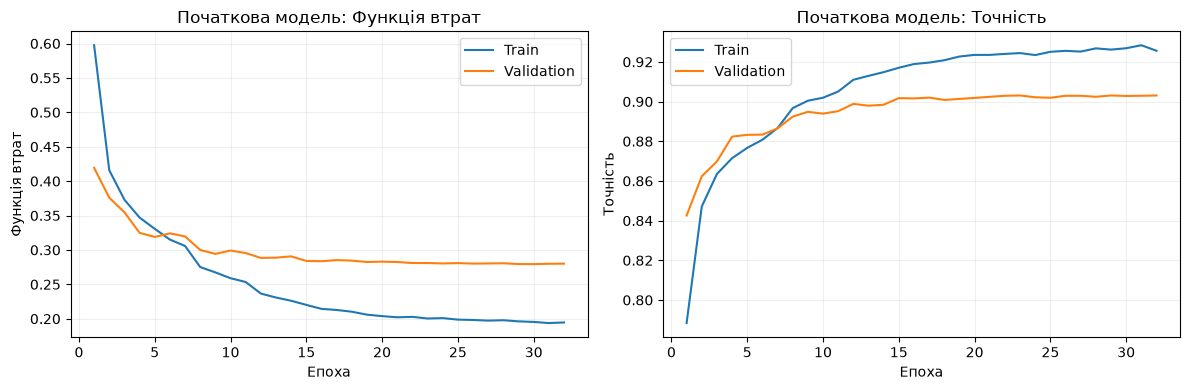

In [9]:
def plot_history(training_history,title):
    values=training_history.history
    epochs=np.arange(1,len(values['loss'])+1)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,metric,label in zip(axes,['loss','accuracy'],['Функція втрат','Точність']):
        ax.plot(epochs,values[metric],label='Train')
        ax.plot(epochs,values['val_'+metric],label='Validation')
        ax.set(xlabel='Епоха',ylabel=label,title=title+': '+label)
        ax.legend()
        ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
plot_history(history,'Початкова модель')

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

Test loss: 0.3088
Test accuracy: 0.8927
Поріг 0.87 виконано: True
                precision    recall  f1-score   support

Футболка / топ     0.8436    0.8520    0.8478      1000
         Штани     0.9908    0.9730    0.9818      1000
         Светр     0.7984    0.8160    0.8071      1000
         Сукня     0.8977    0.8950    0.8963      1000
        Пальто     0.8002    0.8370    0.8182      1000
       Сандалі     0.9737    0.9630    0.9683      1000
       Сорочка     0.7404    0.6930    0.7159      1000
      Кросівки     0.9412    0.9610    0.9510      1000
         Сумка     0.9761    0.9800    0.9780      1000
      Черевики     0.9637    0.9570    0.9604      1000

      accuracy                         0.8927     10000
     macro avg     0.8926    0.8927    0.8925     10000
  weighted avg     0.8926    0.8927    0.8925     10000



,Клас,Кількість помилок
6,Сорочка,307
2,Светр,184
4,Пальто,163
0,Футболка / топ,148
3,Сукня,105
9,Черевики,43
7,Кросівки,39
5,Сандалі,37
1,Штани,27
8,Сумка,20


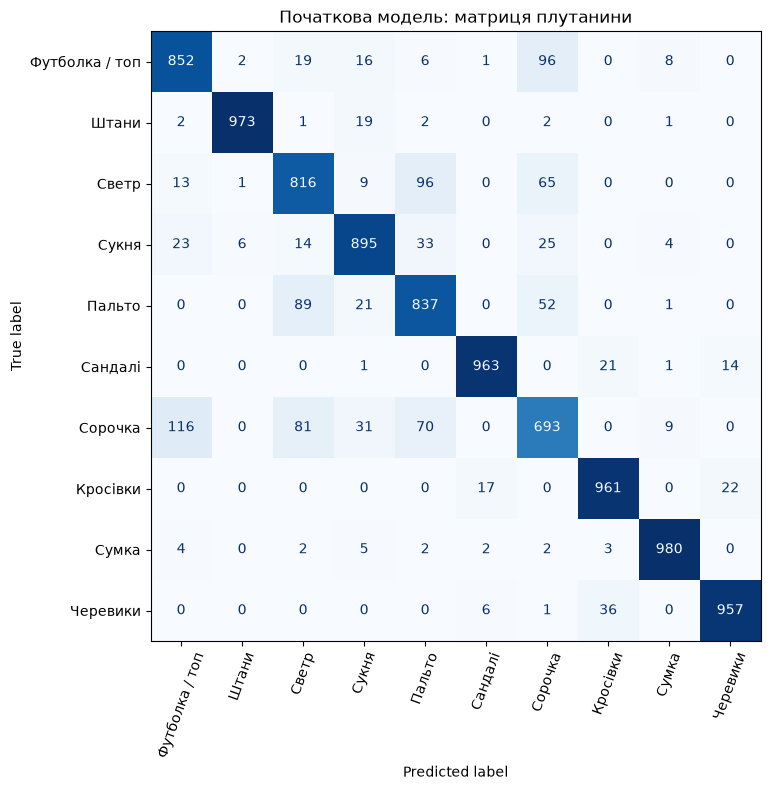

In [10]:
base_loss,base_accuracy=model.evaluate(x_test,y_test,verbose=0)
base_probabilities=model.predict(x_test,batch_size=256,verbose=0)
base_classes=base_probabilities.argmax(axis=1)
print(f'Test loss: {base_loss:.4f}')
print(f'Test accuracy: {base_accuracy:.4f}')
print('Поріг 0.87 виконано:',base_accuracy>=0.87)
print(classification_report(y_test,base_classes,target_names=class_names,digits=4,zero_division=0))
base_confusion=confusion_matrix(y_test,base_classes)
base_errors=base_confusion.sum(axis=1)-base_confusion.diagonal()
error_table=pd.DataFrame({'Клас':class_names,'Кількість помилок':base_errors}).sort_values('Кількість помилок',ascending=False)
display(error_table)
fig,ax=plt.subplots(figsize=(10,8))
ConfusionMatrixDisplay(base_confusion,display_labels=class_names).plot(ax=ax,cmap='Blues',xticks_rotation=70,colorbar=False)
ax.set_title('Початкова модель: матриця плутанини')
plt.tight_layout()
plt.show()

### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

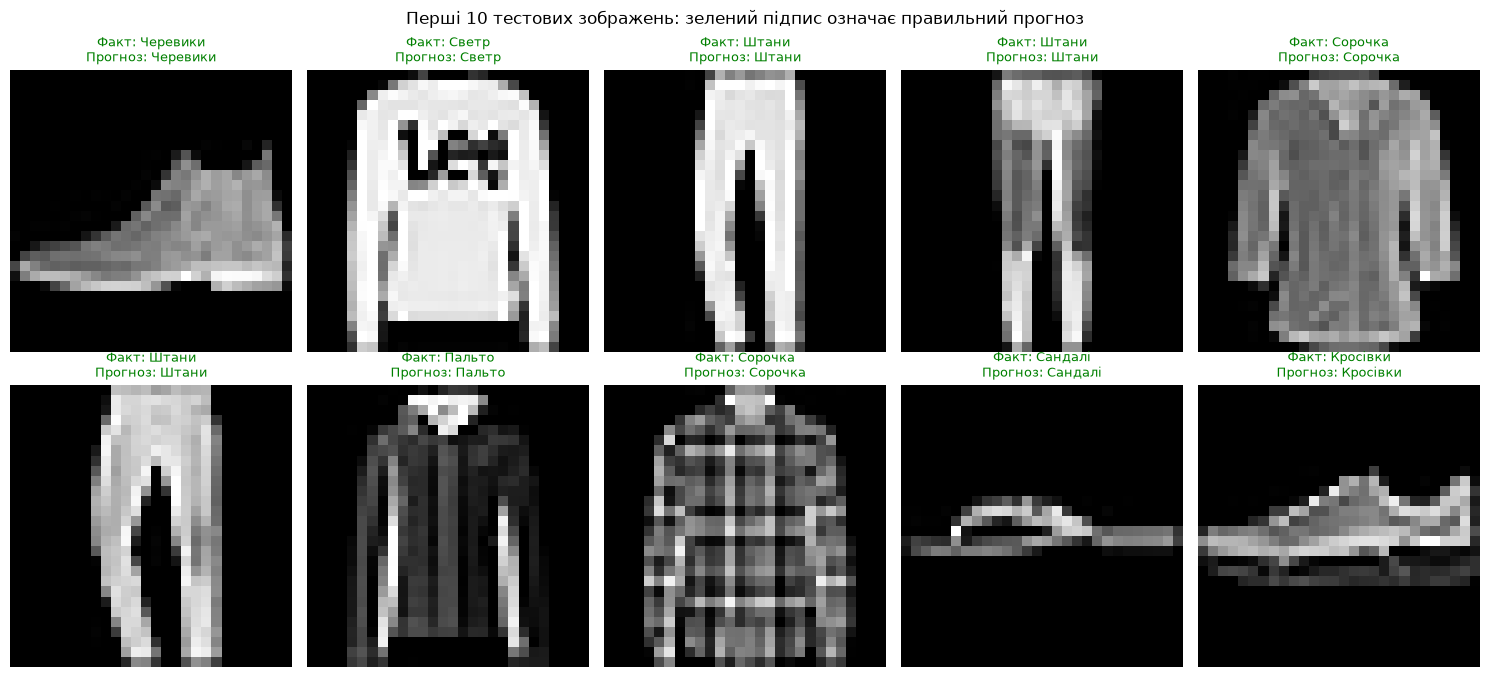

In [11]:
sample_indices=np.arange(10)
fig,axes=plt.subplots(2,5,figsize=(15,7))
for index,ax in zip(sample_indices,axes.flat):
    predicted=int(base_classes[index])
    actual=int(y_test[index])
    ax.imshow(x_test[index],cmap='gray')
    color='green' if predicted==actual else 'red'
    ax.set_title('Факт: '+class_names[actual]+'\nПрогноз: '+class_names[predicted],color=color,fontsize=9)
    ax.axis('off')
plt.suptitle('Перші 10 тестових зображень: зелений підпис означає правильний прогноз')
plt.tight_layout()
plt.show()

**Проміжний висновок.** Початкова мережа має тестову accuracy **0.8927** (89.27%) і loss 0.3088. Вимогу не нижче 0,87 виконано. Найбільше помилок серед справжніх класів отримано для: Сорочка, Светр, Пальто. Ці категорії містять схожі за формою предмети одягу, що видно з матриці плутанини. Кількість епох і найкращі ваги визначалися тільки за validation, а не за test.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [13]:
import importlib.util
import subprocess
import sys
if importlib.util.find_spec('keras_tuner') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','keras-tuner==1.4.8'])
import keras_tuner as kt
from tensorflow.keras.layers import Dense,Flatten,Dropout
from tensorflow.keras.regularizers import l2
print('Keras Tuner:',kt.__version__)

Keras Tuner: 1.4.8


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [14]:
print('Для пошуку:',x_train.shape,y_train.shape)
print('Для validation:',x_val.shape,y_val.shape)
print('Test не передається до tuner.search')

Для пошуку: (48000, 28, 28) (48000,)
Для validation: (12000, 28, 28) (12000,)
Test не передається до tuner.search


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1-3)**, **кількості нейронів (32-512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [15]:
def build_model(hp):
    candidate=keras.Sequential([keras.layers.Input(shape=(28,28)),Flatten()])
    hidden_layers=hp.Int('hidden_layers',min_value=1,max_value=3)
    for layer_index in range(hidden_layers):
        units=hp.Int('units_'+str(layer_index+1),min_value=32,max_value=512,step=32)
        candidate.add(Dense(units,activation='relu',kernel_regularizer=l2(0.0001)))
        candidate.add(Dropout(0.2))
    candidate.add(Dense(10,activation='softmax'))
    learning_rate=hp.Choice('learning_rate',values=[0.01,0.001,0.0001])
    candidate.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return candidate
print('Області пошуку: 1-3 прихованих шари, 32-512 нейронів із кроком 32, learning_rate 0.01/0.001/0.0001')

Області пошуку: 1-3 прихованих шари, 32-512 нейронів із кроком 32, learning_rate 0.01/0.001/0.0001


### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [16]:
tuner=kt.RandomSearch(build_model,objective='val_accuracy',max_trials=3,executions_per_trial=1,seed=42,directory='keras_tuner_results',project_name='fashion_mnist_lab10',overwrite=True)
tuner.search_space_summary()

Search space summary
Default search space size: 3
hidden_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_1 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [17]:
tuner.search(x_train,y_train,validation_data=(x_val,y_val),epochs=20,batch_size=128,callbacks=make_callbacks(),verbose=2)
tuner.results_summary(num_trials=3)
best_hp=tuner.get_best_hyperparameters(num_trials=1)[0]
best_parameters=best_hp.values
print('Найкращі гіперпараметри:',best_parameters)
trial_rows=[]
for trial in tuner.oracle.trials.values():
    trial_rows.append({'Спроба':trial.trial_id,'Статус':trial.status,'Найкраща val_accuracy':trial.score,'Параметри':trial.hyperparameters.values})
display(pd.DataFrame(trial_rows).sort_values('Найкраща val_accuracy',ascending=False))
keras.utils.set_random_seed(42)
tuned_model=tuner.hypermodel.build(best_hp)
tuned_model.summary()
tuned_history=tuned_model.fit(x_train,y_train,validation_data=(x_val,y_val),epochs=32,batch_size=128,callbacks=make_callbacks(),verbose=2)

Trial 3 Complete [00h 00m 21s]
val_accuracy: 0.8870000243186951

Best val_accuracy So Far: 0.9016666412353516
Total elapsed time: 00h 01m 12s
Results summary
Results in keras_tuner_results\fashion_mnist_lab10
Showing 3 best trials
Objective(name="val_accuracy", direction="max")

Trial 1 summary
Hyperparameters:
hidden_layers: 1
units_1: 480
learning_rate: 0.001
units_2: 288
Score: 0.9016666412353516

Trial 2 summary
Hyperparameters:
hidden_layers: 1
units_1: 256
learning_rate: 0.01
units_2: 512
Score: 0.8870000243186951

Trial 0 summary
Hyperparameters:
hidden_layers: 2
units_1: 32
learning_rate: 0.001
units_2: 32
Score: 0.8778333067893982
Найкращі гіперпараметри: {'hidden_layers': 1, 'units_1': 480, 'learning_rate': 0.001, 'units_2': 288}


,Спроба,Статус,Найкраща val_accuracy,Параметри
1,1,COMPLETED,0.901667,"{'hidden_layers': 1, 'units_1': 480, 'learning..."
2,2,COMPLETED,0.887000,"{'hidden_layers': 1, 'units_1': 256, 'learning..."
0,0,COMPLETED,0.877833,"{'hidden_layers': 2, 'units_1': 32, 'learning_..."


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 381,610 (1.46 MB)

 Trainable params: 381,610 (1.46 MB)

... (61 outputs left out)

Epoch 31/32


375/375 - 1s - 3ms/step - accuracy: 0.9328 - loss: 0.2335 - val_accuracy: 0.9014 - val_loss: 0.3230 - learning_rate: 2.5000e-04


Epoch 32/32


375/375 - 1s - 3ms/step - accuracy: 0.9340 - loss: 0.2308 - val_accuracy: 0.9019 - val_loss: 0.3223 - learning_rate: 2.5000e-04


### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Tuned test loss: 0.3494
Tuned test accuracy: 0.8928


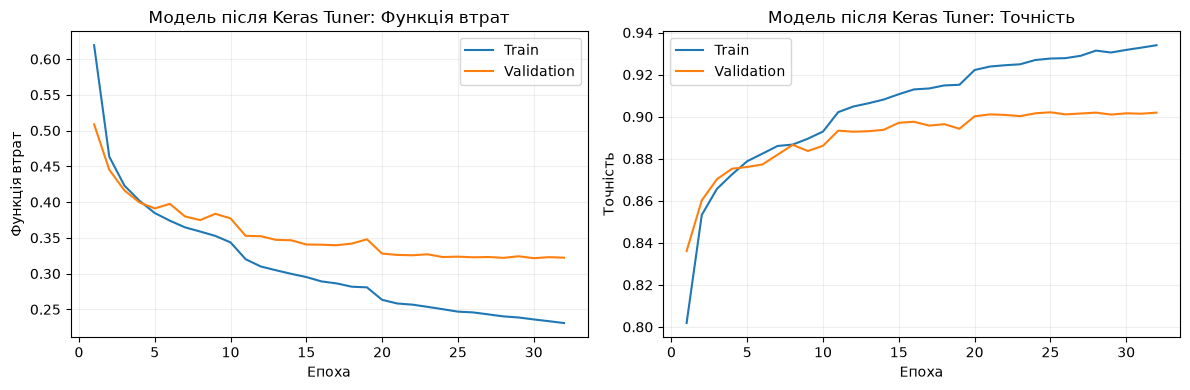

Налаштовану модель збережено та перевірено повторним завантаженням


In [18]:
tuned_loss,tuned_accuracy=tuned_model.evaluate(x_test,y_test,verbose=0)
print(f'Tuned test loss: {tuned_loss:.4f}')
print(f'Tuned test accuracy: {tuned_accuracy:.4f}')
plot_history(tuned_history,'Модель після Keras Tuner')
tuned_model.save('fashion_mnist_tuned.keras')
restored_tuned=keras.models.load_model('fashion_mnist_tuned.keras')
np.testing.assert_allclose(tuned_model(x_val[:16],training=False).numpy(),restored_tuned(x_val[:16],training=False).numpy(),rtol=1e-5,atol=1e-6)
print('Налаштовану модель збережено та перевірено повторним завантаженням')

## Висновки. Порівняння моделей

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 1 |
| Кількість нейронів | 256, 128 | 480 |
| Початкова швидкість навчання | 0.001 | 0.001 |
| Test accuracy | 0.8927 | 0.8928 |
| Test loss | 0.3088 | 0.3494 |
| Кількість епох навчання | 32 | 32 |

Початкова мережа досягла accuracy 0.8927, тому вимогу не нижче 0,87 виконано. Автоматична оптимізація покращила тестову точність: зміна становить +0.01 відсоткового пункту. Найкраща з трьох перевірених конфігурацій за val_accuracy має один прихований шар на 480 нейронів та початкову швидкість навчання 0.001. Це найкращий результат лише серед трьох випадкових спроб, а не доведений глобальний оптимум. Dropout і L2 обмежують перенавчання, EarlyStopping повертає ваги з найменшим val_loss, а ReduceLROnPlateau зменшує крок оптимізатора при зупинці покращення. Найбільше помилок початкової мережі отримано для класів Сорочка, Светр, Пальто; близькі силуети одягу ускладнюють їх розрізнення. Результат може відрізнятися через випадкову ініціалізацію ваг, Dropout, порядок пакетів і особливості обчислень CPU/GPU, хоча початковий seed зафіксовано. Test не використовувався для пошуку або ранньої зупинки, а обидві моделі та їхні прогнози після повторного завантаження перевірено.

Різниця точності становить лише одне правильно класифіковане зображення з 10 000. Водночас test loss налаштованої моделі зріс з 0,3088 до 0,3494, тому переконливої переваги автоматичного підбору в цьому запуску немає.